# 03 · IPC: pasar todo a pesos constantes de 2025

**Proyecto:** ¿Acacías vive del petróleo? Regalías vs. desarrollo
**Fuente:** DANE, *Índices – series de empalme*, octubre 2026. Base diciembre 2018 = 100.
**Descarga:** 24/11/2026

**¿Por qué?** 1.000 millones de 2013 no compran lo mismo que 1.000 millones de 2025. Para comparar años hay que llevar todo a **pesos de un mismo año**. Aquí usamos **pesos de 2025**, el último año completo.

**Fórmula:**
$$\text{valor constante} = \text{valor corriente} \times \frac{\text{IPC promedio 2025}}{\text{IPC promedio del año}}$$

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.float_format", "{:,.2f}".format)

RAW = Path("../data/ipc/anex-IPC-Indices-oct2026.xlsx")
OUT = Path("../data processed")
ANIO_BASE = 2025

## 1. Leer el IPC

El Excel viene en formato **ancho**: una fila por mes y una columna por año. Además tiene títulos arriba y notas abajo. Hay que ubicar la fila del encabezado (`Mes`) y quedarse solo con las 12 filas de meses.

In [2]:
raw = pd.read_excel(RAW, header=None)
fila_enc = raw.index[raw[0] == "Mes"][0]

ipc_ancho = raw.iloc[fila_enc + 1: fila_enc + 13].copy()
ipc_ancho.columns = ["mes"] + [int(a) for a in raw.iloc[fila_enc, 1:]]
ipc_ancho

,mes,2003,2004,2005,2006,2007,2008,2009,2010,2011,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
9,Enero,50.42,53.54,56.45,59.02,61.80,65.51,70.21,71.69,74.12,...,94.07,97.53,100.60,104.24,105.91,113.26,128.27,138.98,146.24,154.07
10,Febrero,50.98,54.18,57.02,59.41,62.53,66.50,70.80,72.28,74.57,...,95.01,98.22,101.18,104.94,106.58,115.11,130.40,140.49,147.90,155.73
11,Marzo,51.51,54.71,57.46,59.83,63.29,67.04,71.15,72.46,74.77,...,95.46,98.45,101.62,105.53,107.12,116.26,131.77,141.48,148.68,156.94
12,Abril,52.10,54.96,57.72,60.09,63.85,67.51,71.38,72.79,74.86,...,95.91,98.91,102.12,105.70,107.76,117.71,132.80,142.32,149.66,158.17
13,Mayo,52.36,55.17,57.95,60.29,64.05,68.14,71.39,72.87,75.07,...,96.12,99.16,102.44,105.36,108.84,118.70,133.38,142.92,150.14,158.91
14,Junio,52.33,55.51,58.18,60.48,64.12,68.73,71.35,72.95,75.31,...,96.23,99.31,102.71,104.97,108.78,119.31,133.78,143.38,150.30,159.53
15,Julio,52.26,55.49,58.21,60.73,64.23,69.06,71.32,72.92,75.42,...,96.18,99.18,102.94,104.97,109.14,120.27,134.45,143.67,150.71,159.79
16,Agosto,52.42,55.51,58.21,60.96,64.14,69.19,71.35,73.00,75.39,...,96.32,99.30,103.03,104.96,109.62,121.50,135.39,143.67,150.99,160.42
17,Septiembre,52.53,55.67,58.46,61.14,64.20,69.06,71.28,72.90,75.62,...,96.36,99.47,103.26,105.29,110.04,122.63,136.11,144.02,151.48,161
18,Octubre,52.56,55.66,58.60,61.05,64.20,69.30,71.19,72.84,75.77,...,96.37,99.59,103.43,105.23,110.06,123.51,136.45,143.83,151.76,161.32


In [3]:
MESES = ["Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio", "Julio",
         "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"]

ipc_mensual = ipc_ancho.melt(id_vars="mes", var_name="anio", value_name="ipc").dropna()
ipc_mensual["mes_num"] = ipc_mensual["mes"].str.strip().map({m: i + 1 for i, m in enumerate(MESES)})
ipc_mensual["fecha"] = pd.to_datetime(dict(year=ipc_mensual["anio"], month=ipc_mensual["mes_num"], day=1))
ipc_mensual["ipc"] = ipc_mensual["ipc"].astype(float)
ipc_mensual = ipc_mensual.sort_values("fecha")[["fecha", "anio", "mes_num", "ipc"]].reset_index(drop=True)

print(ipc_mensual["fecha"].min().date(), "a", ipc_mensual["fecha"].max().date())
print("Diciembre 2018 =", ipc_mensual.loc[ipc_mensual["fecha"] == "2018-12-01", "ipc"].item(), "(debe ser 100)")

2003-01-01 a 2026-10-01
Diciembre 2018 = 100.0 (debe ser 100)


## 2. IPC anual y factor de conversión

In [4]:
ipc_anual = ipc_mensual.groupby("anio").agg(ipc_promedio=("ipc", "mean"), meses=("ipc", "size"))
ipc_anual["inflacion_anual_pct"] = 100 * ipc_anual["ipc_promedio"].pct_change()
ipc_anual[f"factor_a_pesos_{ANIO_BASE}"] = ipc_anual.loc[ANIO_BASE, "ipc_promedio"] / ipc_anual["ipc_promedio"]
ipc_anual.loc[2012:]

,ipc_promedio,meses,inflacion_anual_pct,factor_a_pesos_2025
anio,,,,
2012,77.63,12,3.17,1.93
2013,79.20,12,2.02,1.90
2014,81.50,12,2.90,1.84
2015,85.56,12,4.99,1.76
2016,91.99,12,7.51,1.63
2017,95.96,12,4.32,1.56
2018,99.07,12,3.24,1.52
2019,102.56,12,3.52,1.46
2020,105.15,12,2.53,1.43


**Cómo leerlo:** el factor de 2013 es cercano a 1,9. Es decir, **1 peso de 2013 equivale a unos 1,9 pesos de 2025**.

⚠️ 2026 solo tiene datos hasta octubre, así que su promedio es parcial.

**Validación:** la inflación de diciembre a diciembre de 2022 debe dar **13,12%**, la cifra oficial que reportó el DANE para 2022.

In [5]:
dic = ipc_mensual[ipc_mensual["mes_num"] == 12].set_index("anio")["ipc"]
print(f"Inflación dic-2021 a dic-2022: {100 * (dic[2022] / dic[2021] - 1):.2f}%")

Inflación dic-2021 a dic-2022: 13.12%


## 3. Aplicar a las tablas de regalías

In [6]:
factor = ipc_anual[f"factor_a_pesos_{ANIO_BASE}"]

def a_constantes(df, columnas, col_anio="anio"):
    df = df.copy()
    f = df[col_anio].map(factor)
    for c in columnas:
        df[f"{c}_const{ANIO_BASE}"] = df[c] * f
    return df

# Generado vs. recibido (Acacías)
gvr = pd.read_csv(OUT / "acacias_generado_vs_recibido.csv")
gvr = a_constantes(gvr, ["regalias_generadas_anh", "plan_recursos_total", "asignaciones_directas_recibidas"])

# Producción y regalías por municipio (ANH)
anh = a_constantes(pd.read_csv(OUT / "anh_municipios_anual.csv"), ["regalias_cop"])

# Recaudo por municipio (SICODIS)
sic = a_constantes(pd.read_csv(OUT / "sicodis_municipios_anual.csv", dtype={"cod_dane": str}), ["total_pbc", "total_recaudo"])

cols = ["anio", f"regalias_generadas_anh_const{ANIO_BASE}", f"asignaciones_directas_recibidas_const{ANIO_BASE}"]
(gvr[cols].set_index("anio") / 1e9).round(1).rename(columns=lambda c: c.replace(f"_const{ANIO_BASE}", " (miles de millones de 2025)"))

,regalias_generadas_anh (miles de millones de 2025),asignaciones_directas_recibidas (miles de millones de 2025)
anio,,
2013,680.60,25.70
2014,678.80,24.90
2015,397.10,17.30
2016,305.10,5.40
2017,503.20,12.60
2018,688.60,17.80
2019,721.80,15.70
2020,291.50,7.50
2021,828.30,63.10


## 4. Corriente vs. constante

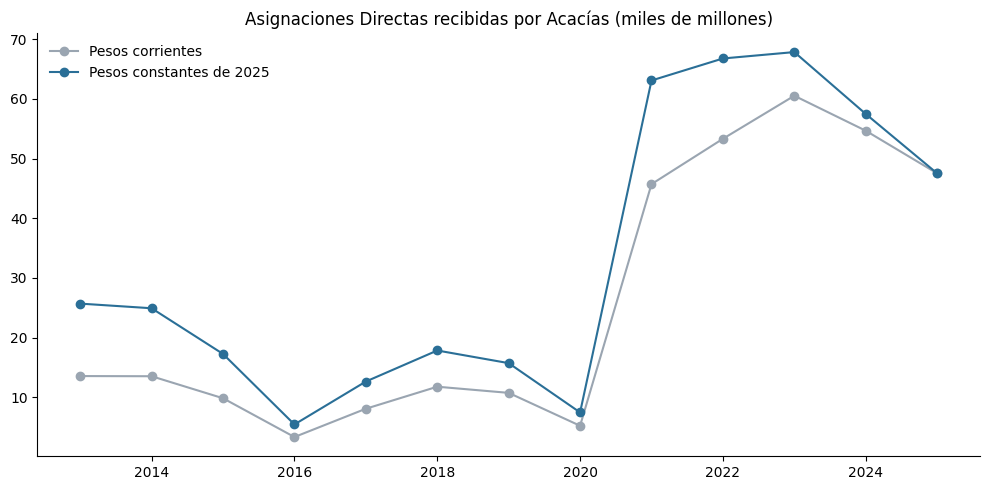

In [7]:
g = gvr.set_index("anio").loc[2013:2025]

fig, ax = plt.subplots(figsize=(10, 5))
(g["asignaciones_directas_recibidas"] / 1e9).plot(ax=ax, marker="o", color="#9aa5b1", label="Pesos corrientes")
(g[f"asignaciones_directas_recibidas_const{ANIO_BASE}"] / 1e9).plot(ax=ax, marker="o", color="#2a6f97", label=f"Pesos constantes de {ANIO_BASE}")
ax.set_title("Asignaciones Directas recibidas por Acacías (miles de millones)")
ax.set_xlabel("")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

Los años viejos "crecen" al pasarlos a pesos de hoy. Por ejemplo, lo que recibió Acacías en 2013 vale casi el doble en pesos de 2025. Sin este ajuste, el salto de 2021 se vería más grande de lo que realmente es.

## 5. Exportar

In [8]:
ipc_mensual.to_csv(OUT / "ipc_mensual.csv", index=False, encoding="utf-8-sig")
ipc_anual.reset_index().to_csv(OUT / "ipc_anual.csv", index=False, encoding="utf-8-sig")
gvr.to_csv(OUT / "acacias_generado_vs_recibido.csv", index=False, encoding="utf-8-sig")
anh.to_csv(OUT / "anh_municipios_anual.csv", index=False, encoding="utf-8-sig")
sic.to_csv(OUT / "sicodis_municipios_anual.csv", index=False, encoding="utf-8-sig")
print("Listo: ipc_mensual.csv, ipc_anual.csv y columnas *_const2025 agregadas a 3 tablas")

Listo: ipc_mensual.csv, ipc_anual.csv y columnas *_const2025 agregadas a 3 tablas


> **Nota:** este notebook **sobrescribe** tres tablas del 01 y el 02 agregándoles columnas `_const2025`. Si vuelves a correr el 01 o el 02, corre también este.